In [17]:
from sklearn.datasets import make_moons

X, y =make_moons(n_samples=2400, noise=0.25, random_state=2026) #create data
X.shape

(2400, 2)

In [18]:
import numpy as np
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test= train_test_split(X, y, test_size = 0.2, random_state = 2026, stratify = y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size = 0.25, random_state = 2026,stratify = y_temp )
# train test split data to train, test, val
print(
    f'X_train - {len(X_train)}, X_test - {len(X_test)}, X_val - {len(X_val)}')
print(f'classes train - {np.bincount(y_train)}, classes test - {np.bincount(y_test)}, classes val - {np.bincount(y_val)}')

X_train - 1440, X_test - 480, X_val - 480
classes train - [720 720], classes test - [240 240], classes val - [240 240]


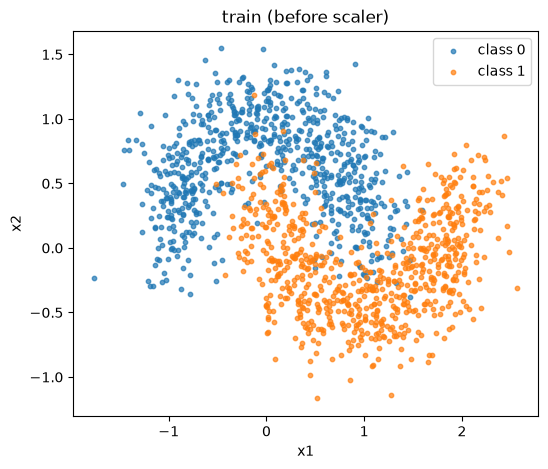

In [19]:
import matplotlib.pyplot as plt
import os
# first graphik before standartscaler
os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(6, 5))
for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
    m = y_train == cls
    plt.scatter(X_train[m, 0], X_train[m, 1], s=10, alpha=0.7, c=color, label=f"class {cls}")
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("train (before scaler)")
plt.legend()
plt.savefig("figures/train_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
from sklearn.preprocessing import StandardScaler

scaler =StandardScaler().fit(X_train) #standartization of data n float 32 fo torch
X_train_s = scaler.transform(X_train).astype(np.float32)
X_val_s = scaler.transform(X_val).astype(np.float32)
X_test_s = scaler.transform(X_test).astype(np.float32)

print("train mean:", X_train_s.mean(axis=0))
print("train std: ", X_train_s.std(axis=0))
print("val mean:  ", X_val_s.mean(axis=0))
print("val std: ", X_val_s.std(axis=0))

train mean: [-7.9472864e-09  1.3493829e-08]
train std:  [0.9999996 0.9999997]
val mean:   [-0.08968209  0.00520011]
val std:  [0.9790457 1.0047251]


In [33]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device("cpu")
torch.set_num_threads(1)

# tensors
Xtr=torch.tensor(X_train_s, dtype=torch.float32)
Xva = torch.tensor(X_val_s,   dtype=torch.float32)
Xte = torch.tensor(X_test_s,  dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.long)
yva = torch.tensor(y_val,   dtype=torch.long)
yte = torch.tensor(y_test,  dtype=torch.long)

BATCH_SIZE = 128
EPOCHS = 100
WIDTH = 32

# train dataloaders w batchsize=128 n random shuffle
def make_train_loader(seed):
    g =torch.Generator().manual_seed(10000 + seed)
    return DataLoader(TensorDataset(Xtr, ytr), batch_size=BATCH_SIZE,
                      shuffle=True, generator=g)

print(len(Xtr), len(Xva), len(Xte), np.bincount(yva.numpy()))

1440 480 480 [240 240]


In [22]:
ACTIVATIONS={"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}

class MLP(nn.Module):
    def __init__(self, n_hidden, activation, width=WIDTH, in_dim=2, out_dim=2):
        super().__init__()
        self.hidden=nn.ModuleList() # save hidden layers fo gradients  
        layers=[]
        d=in_dim
        for _ in range(n_hidden): #hidden layers creation
            l=nn.Linear(d, width)
            self.hidden.append(l)
            layers+=[l, ACTIVATIONS[activation]()] # add them into layers w activations which would be taken from dict
            d=width # in features change 2->32->32->32 ....
        self.out=nn.Linear(width, out_dim) # in 32 out 2 (logits)
        layers.append(self.out)
        self.net=nn.Sequential(*layers) #to use w different amount of layers

    def forward(self, x):
        return self.net(x)

def init_weights(model, hidden_init):
    for lin in model.hidden:
        if hidden_init == "xavier":  #init w xavier (sobased)
            nn.init.xavier_normal_(lin.weight, gain=1.0)
        elif hidden_init == "he":  #init w kaiming
            nn.init.kaiming_normal_(lin.weight, mode="fan_in", nonlinearity="relu")
        else:
            raise ValueError(hidden_init)
        nn.init.zeros_(lin.bias)
    nn.init.xavier_normal_(model.out.weight, gain=1.0)
    nn.init.zeros_(model.out.bias)

def  build_model(n_hidden, activation, hidden_init, seed): #build model w diff hidden layers, activations n hidden layers init
    torch.manual_seed(seed)
    model=MLP(n_hidden, activation)
    init_weights(model, hidden_init)
    return model.to(DEVICE)


In [23]:
def expected_params(n_hidden, width=WIDTH, in_dim=2, out_dim=2):
    total = in_dim * width + width                          # first hiden
    total += (n_hidden - 1) * (width * width + width)       # other hidden
    total += width * out_dim + out_dim                      # out lay
    return total

criterion = nn.CrossEntropyLoss(reduction="mean")

for L in [1, 6]:
    m = build_model(L, "relu", "he", seed=11)
    xb, yb = Xtr[:8], ytr[:8]
    out = m(xb)
    loss = criterion(out, yb)
    print(f"L={L}: in-{tuple(xb.shape)}, out-{tuple(out.shape)}, loss.dim()={loss.dim()}")

    n_real = sum(p.numel() for p in m.parameters())
    print(f"params: formula={expected_params(L)}, numel={n_real}, ok={expected_params(L)==n_real}")

    m.zero_grad()
    loss.backward()
    for i, lin in enumerate(m.hidden, 1):
        g = lin.weight.grad
        assert g is not None and g.shape == lin.weight.shape and torch.isfinite(g).all()
    print(f"gradients of all {L} hidden layers:exist, shapes good, limited")

L=1: in-(8, 2), out-(8, 2), loss.dim()=0
params: formula=162, numel=162, ok=True
gradients of all 1 hidden layers:exist, shapes good, limited
L=6: in-(8, 2), out-(8, 2), loss.dim()=0
params: formula=5442, numel=5442, ok=True
gradients of all 6 hidden layers:exist, shapes good, limited


In [24]:
import copy

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item() #criterion still crossentropy from test output which previous code window
        acc = (logits.argmax(dim=1) == y).float().mean().item() #accuracy: max from pair of logits to float, then mean of that and convert to scalar
    return loss, acc

X_probe, y_probe = Xtr[:128], ytr[:128]   # first 128 with same order

# forward/backward on batch 128
def probe_grad_norms(model):
    model.eval()
    model.zero_grad(set_to_none=True)
    loss = criterion(model(X_probe), y_probe)
    loss.backward()
    norms = [lin.weight.grad.norm().item() for lin in model.hidden]  # .norm() fo Frobenius matrix
    model.zero_grad(set_to_none=True)
    return norms

CONFIGS = {
    "A": dict(n_hidden=6, activation="sigmoid", init="xavier", opt="adam", lr=0.003),
    "B": dict(n_hidden=6, activation="tanh",    init="xavier", opt="adam", lr=0.003),
    "C": dict(n_hidden=6, activation="relu",    init="xavier", opt="adam", lr=0.003),
    "D": dict(n_hidden=6, activation="relu",    init="he",     opt="adam", lr=0.003),
    "E": dict(n_hidden=6, activation="relu",    init="he",     opt="sgd",  lr=0.05),
    "F": dict(n_hidden=1, activation="relu",    init="he",     opt="adam", lr=0.003),
} 
SEEDS = [11, 29]
GRAD_CONFIGS = {"A", "C", "D"}
GRAD_EPOCHS = {0, 20, 100}

def make_optimizer(name, params, lr):
    if name == "adam":
        return torch.optim.Adam(params, lr = lr)
    if name == "sgd":
        return torch.optim.SGD(params, lr = lr, momentum =0)
    raise ValueError(name)

def run_experiment(cfg_name, seed):
    cfg = CONFIGS[cfg_name]
    model = build_model(cfg["n_hidden"], cfg["activation"], cfg["init"], seed)
    optimizer = make_optimizer(cfg["opt"], model.parameters(), cfg["lr"])
    loader = make_train_loader(seed)
    do_grads = cfg_name in GRAD_CONFIGS

    history, grads = [], []

    def log(epoch):
        tr_loss, tr_acc = evaluate(model, Xtr, ytr)
        va_loss, va_acc = evaluate(model, Xva, yva)
        assert np.isfinite(tr_loss) and np.isfinite(va_loss), f"{cfg_name}/{seed}: loss not limited on epoch {epoch}"
        history.append(dict(config = cfg_name, seed = seed, epoch = epoch,
                            train_loss = tr_loss, train_accuracy = tr_acc,
                            val_loss = va_loss, val_accuracy = va_acc))
        if do_grads and epoch in GRAD_EPOCHS:
            for layer, g in enumerate(probe_grad_norms(model), 1):
                grads.append(dict(config= cfg_name, seed = seed, epoch = epoch, layer = layer, gradient_norm = g))

    log(0)                                   # epoch 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            logits= model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
        log(epoch)                           #after every epoch

    state = copy.deepcopy(model.state_dict())  # save weights fo future task
    return history, grads, state

In [26]:
import pandas as pd

# run all epochs and collect dataframes 
os.makedirs("results", exist_ok=True)

all_history, all_grads, states = [], [], {}
for cfg_name in CONFIGS:
    for seed in SEEDS:
        h, g, st = run_experiment(cfg_name, seed)
        all_history += h
        all_grads += g
        states[(cfg_name, seed)] = st
        last = h[-1]
        print(f"{cfg_name}/{seed}: train_loss={last['train_loss']:.4f} "
              f"val_loss={last['val_loss']:.4f} val_acc={last['val_accuracy']:.4f}")

metrics_df = pd.DataFrame(all_history)
grads_df = pd.DataFrame(all_grads)
metrics_df.to_csv("results/metrics.csv", index=False)
grads_df.to_csv("results/gradient_norms.csv", index=False)

print(metrics_df.shape, grads_df.shape)

A/11: train_loss=0.1505 val_loss=0.1907 val_acc=0.9167
A/29: train_loss=0.1403 val_loss=0.1771 val_acc=0.9167
B/11: train_loss=0.1467 val_loss=0.2034 val_acc=0.9125
B/29: train_loss=0.1436 val_loss=0.1893 val_acc=0.9187
C/11: train_loss=0.1209 val_loss=0.1803 val_acc=0.9250
C/29: train_loss=0.1255 val_loss=0.2073 val_acc=0.9167
D/11: train_loss=0.1091 val_loss=0.2192 val_acc=0.9083
D/29: train_loss=0.1104 val_loss=0.2256 val_acc=0.8979
E/11: train_loss=0.2348 val_loss=0.3261 val_acc=0.8625
E/29: train_loss=0.3074 val_loss=0.3597 val_acc=0.8438
F/11: train_loss=0.1367 val_loss=0.1678 val_acc=0.9292
F/29: train_loss=0.1382 val_loss=0.1676 val_acc=0.9229
(1212, 7) (108, 5)


In [27]:
final= metrics_df[metrics_df.epoch == EPOCHS]
table = final.pivot(index="config", columns="seed",
                    values=["train_loss", "train_accuracy", "val_loss", "val_accuracy"])
table[("val_loss", "mean")] = final.groupby("config")["val_loss"].mean()
table = table.round(4)
table.to_csv("results/comparison_epoch100.csv")
table

train_loss         train_accuracy         val_loss          \
seed           11      29             11      29       11      29   
config                                                              
A          0.1505  0.1403         0.9458  0.9458   0.1907  0.1771   
B          0.1467  0.1436         0.9465  0.9486   0.2034  0.1893   
C          0.1209  0.1255         0.9514  0.9486   0.1803  0.2073   
D          0.1091  0.1104         0.9528  0.9569   0.2192  0.2256   
E          0.2348  0.3074         0.9000  0.8639   0.3261  0.3597   
F          0.1367  0.1382         0.9493  0.9493   0.1678  0.1676   

       val_accuracy         val_loss  
seed             11      29     mean  
config                                
A            0.9167  0.9167   0.1839  
B            0.9125  0.9187   0.1963  
C            0.9250  0.9167   0.1938  
D            0.9083  0.8979   0.2224  
E            0.8625  0.8438   0.3429  
F            0.9292  0.9229   0.1677

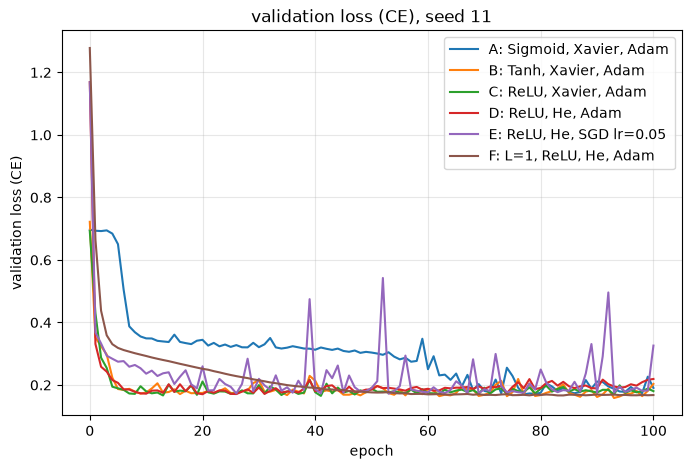

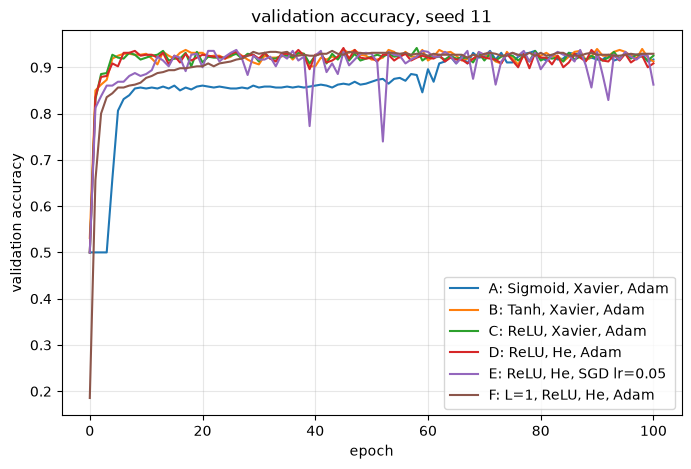

In [28]:
LABELS = {
    "A": "A: Sigmoid, Xavier, Adam",
    "B": "B: Tanh, Xavier, Adam",
    "C": "C: ReLU, Xavier, Adam",
    "D": "D: ReLU, He, Adam",
    "E": "E: ReLU, He, SGD lr=0.05",
    "F": "F: L=1, ReLU, He, Adam",
}

d11 = metrics_df[metrics_df.seed == 11]
for metric, ylabel, fname in [("val_loss", "validation loss (CE)", "val_loss_seed11.png"),
                              ("val_accuracy", "validation accuracy", "val_accuracy_seed11.png")]:
    plt.figure(figsize=(8, 5))
    for cfg in CONFIGS:
        d = d11[d11.config == cfg]
        plt.plot(d.epoch, d[metric], label=LABELS[cfg])
    plt.xlabel("epoch"); plt.ylabel(ylabel)
    plt.title(f"{ylabel}, seed 11")
    plt.legend(); plt.grid(alpha=0.3)
    plt.savefig(f"figures/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

zero norms: 0
non-finite norms: 0


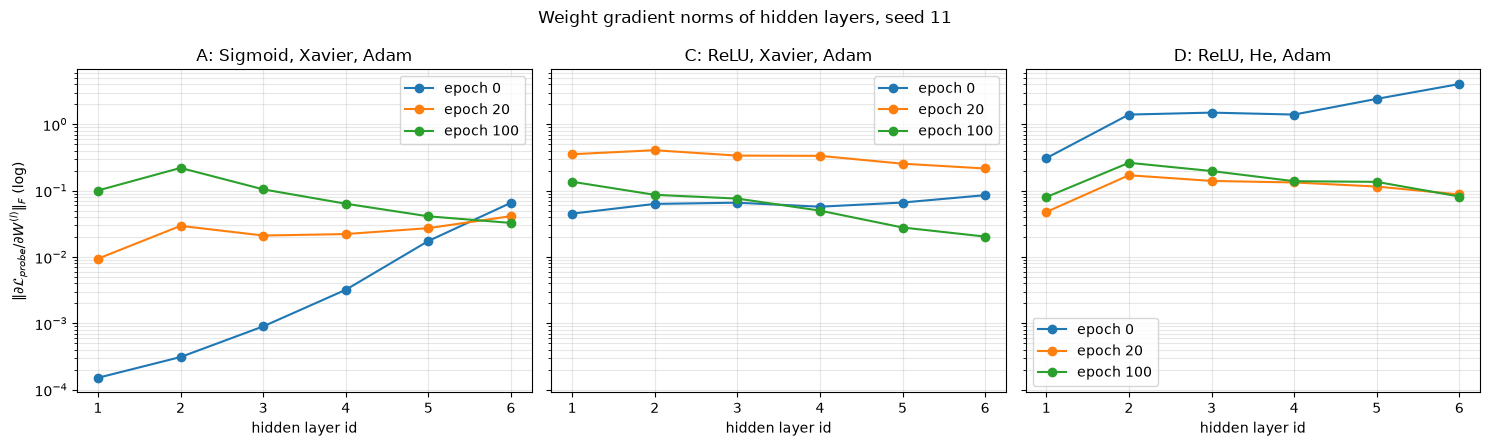

In [29]:
# 4
# zeros cannot be drawn on a log scale-report them instantly
zeros = grads_df[grads_df.gradient_norm == 0]
print("zero norms:", len(zeros))
if len(zeros):
    print(zeros)

# NaN/inf would point to a problem in the probe batch, loss or backward
non_finite = grads_df[~np.isfinite(grads_df.gradient_norm)]
print("non-finite norms:", len(non_finite))
if len(non_finite):
    print(non_finite)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
g11 = grads_df[grads_df.seed == 11]
for ax, cfg in zip(axes, ["A", "C", "D"]):
    for ep in sorted(GRAD_EPOCHS):
        d = g11[(g11.config == cfg) & (g11.epoch == ep) & (g11.gradient_norm > 0)]
        ax.plot(d.layer, d.gradient_norm, marker="o", label=f"epoch {ep}")
    ax.set_yscale("log")
    ax.set_xlabel("hidden layer id")
    ax.set_title(LABELS[cfg])
    ax.set_xticks(range(1, 7))
    ax.grid(alpha=0.3, which="both")
    ax.legend()
axes[0].set_ylabel(r"$\|\partial \mathcal{L}_{probe} / \partial W^{(l)}\|_F$ (log)")
plt.suptitle("Weight gradient norms of hidden layers, seed 11")
plt.tight_layout()
plt.savefig("figures/grad_norms_seed11.png", dpi=150, bbox_inches="tight")
plt.show()

# table for the report where layers used as columns, both seeds
grad_table = grads_df.pivot_table(index=["config", "seed", "epoch"],
                                  columns="layer", values="gradient_norm")
grad_table.style.format("{:.2e}")

In [30]:
# 1-2 mean val_loss at epoch 100 over both seeds, ties-> earlier letter
mean_val = final.groupby("config")["val_loss"].mean().sort_index()
best_cfg = mean_val[mean_val == mean_val.min()].index[0]   # sorted index -> earliest letter wins tie

# 3 within the config-seed with lower val_loss, ties -> seed 11
cand = final[final.config == best_cfg].set_index("seed")["val_loss"]
best_seed = 11 if cand[11] <= cand[29] else 29

print("mean val_loss per config:\n", mean_val.round(4))
print(f"selected: {best_cfg}, seed {best_seed}, val_loss={cand[best_seed]:.4f}")

# 4 test on saved epoch-100 weights
cfg = CONFIGS[best_cfg]
best_model = MLP(cfg["n_hidden"], cfg["activation"])
best_model.load_state_dict(states[(best_cfg, best_seed)])

test_loss, test_acc = evaluate(best_model, Xte, yte)
tr_loss, tr_acc = evaluate(best_model, Xtr, ytr)
va_loss, va_acc = evaluate(best_model, Xva, yva)

summary = pd.DataFrame([
    dict(split="train", loss=tr_loss, accuracy=tr_acc),
    dict(split="validation", loss=va_loss, accuracy=va_acc),
    dict(split="test", loss=test_loss, accuracy=test_acc),
])
summary.insert(0, "seed", best_seed)
summary.insert(0, "config", best_cfg)
summary.to_csv("results/final_model.csv", index=False)
print(summary.round(4))

mean val_loss per config:
 config
A    0.1839
B    0.1963
C    0.1938
D    0.2224
E    0.3429
F    0.1677
Name: val_loss, dtype: float64
selected: F, seed 29, val_loss=0.1676
  config  seed       split    loss  accuracy
0      F    29       train  0.1382    0.9493
1      F    29  validation  0.1676    0.9229
2      F    29        test  0.1314    0.9500


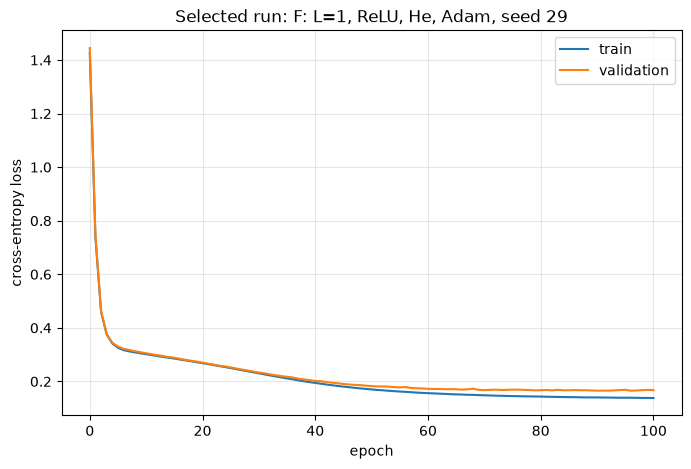

In [31]:
# train/val graph of the selected run
d = metrics_df[(metrics_df.config == best_cfg) & (metrics_df.seed == best_seed)]
plt.figure(figsize=(8, 5))
plt.plot(d.epoch, d.train_loss, label="train")
plt.plot(d.epoch, d.val_loss, label="validation")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss")
plt.title(f"Selected run: {LABELS[best_cfg]}, seed {best_seed}")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("figures/best_run_curves.png", dpi=150, bbox_inches="tight")
plt.show()